In [9]:
import os, io, copy, glob, pickle, time, warnings
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import f1_score, matthews_corrcoef, average_precision_score

warnings.filterwarnings("ignore")

CSV_PATH = None            # None = download from Kaggle exactly like Day 1
NROWS = 1_000_000
ATTACKS_WANTED = ["ddos", "scanning", "password", "xss"]
MIN_TRAIN_ATTACK = 500     # skip an attack if the subsample has fewer train flows than this
SEEDS = [0, 1, 2]
MAX_IF_FIT = 50_000        # benign rows used to fit each Isolation Forest

K_LIST_A = [1, 2, 3, 5, 10, 15, 20, 30, 39]   # Part A (Isolation Forest)
K_LIST_B = [5, 10, 15, 39]                    # federated autoencoder + benchmark
K_MAIN = 10                                   # k for the per-round F1 plot

N_CLIENTS, ALPHA = 5, 0.3  # clients, Dirichlet non-IID strength (smaller = more skewed)
ROUNDS, LOCAL_EPOCHS, BATCH, LR = 15, 1, 512, 1e-3
OUT = "results_day2"
os.makedirs(OUT, exist_ok=True)

In [10]:
if CSV_PATH is None:
    import kagglehub
    path = kagglehub.dataset_download("shahidabbas76/nf-ton-iot-v2-full-dataset")
    CSV_PATH = glob.glob(f"{path}/**/*.csv", recursive=True)[0]
df = pd.read_csv(CSV_PATH, nrows=NROWS)
print("Loaded:", df.shape)

df_sub, _ = train_test_split(df, test_size=0.7, stratify=df["Label"], random_state=42)
att_all = df_sub["Attack"].astype(str).str.lower().values          # keep attack names
drop_cols = ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "L4_DST_PORT", "TIMESTAMP", "Attack"]
df_clean = df_sub.drop(columns=[c for c in drop_cols if c in df_sub.columns])
X = df_clean.drop(columns=["Label"])
y = df_clean["Label"]

X.replace([np.inf, -np.inf], np.nan, inplace=True)
imputer = SimpleImputer(strategy="constant", fill_value=0)
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
const_cols = [c for c in X_imputed.columns if X_imputed[c].nunique() <= 1]
X_imputed = X_imputed.drop(columns=const_cols)

# Same seeds and stratification as Day 1, so the split is identical
X_train, X_temp, y_train, y_temp, a_train, a_temp = train_test_split(
    X_imputed, y, att_all, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test, a_val, a_test = train_test_split(
    X_temp, y_temp, a_temp, test_size=0.5, stratify=y_temp, random_state=42)

scaler = StandardScaler()
X_train_scaled = np.nan_to_num(scaler.fit_transform(X_train), nan=0.0, posinf=0.0, neginf=0.0)
X_val_scaled = np.nan_to_num(scaler.transform(X_val), nan=0.0, posinf=0.0, neginf=0.0)
X_test_scaled = np.nan_to_num(scaler.transform(X_test), nan=0.0, posinf=0.0, neginf=0.0)
y_train, y_val, y_test = y_train.values, y_val.values, y_test.values

benign_mask = y_train == 0
X_train_benign = X_train_scaled[benign_mask]
feat_names = list(X_train.columns)
n_feat = X_train_scaled.shape[1]
print("Train benign:", X_train_benign.shape, "| features:", n_feat)   # Day 1: (108462, 39)

counts = pd.Series(a_train).value_counts()
print("\nTrain flows per class:\n", counts)
ATTACKS = [a for a in ATTACKS_WANTED if counts.get(a, 0) >= MIN_TRAIN_ATTACK]
for a in counts.index:                       # top up to 4 attacks if some wanted ones are missing
    if len(ATTACKS) >= 4: break
    if a != "benign" and a not in ATTACKS and counts[a] >= MIN_TRAIN_ATTACK:
        ATTACKS.append(a)
print("\nAttacks used:", ATTACKS)
K_LIST_A = sorted({k for k in K_LIST_A if k < n_feat} | {n_feat})
K_LIST_B = sorted({k for k in K_LIST_B if k < n_feat} | {n_feat})

Loaded: (1000000, 45)
Train benign: (108462, 39) | features: 39

Train flows per class:
 benign        108462
scanning       70505
password         405
injection        200
dos              164
xss              109
mitm              80
ddos              66
ransomware         9
Name: count, dtype: int64

Attacks used: ['scanning']


In [11]:
def central_welch_t(X, y):
    t = stats.ttest_ind(X[y == 1], X[y == 0], equal_var=False).statistic
    return np.nan_to_num(np.abs(t), nan=0.0, posinf=0.0)

def local_stats(X, y):
    """What ONE client sends: per-class count, sum, sum of squares. No raw flows."""
    return {c: (int((y == c).sum()), X[y == c].sum(0), (X[y == c] ** 2).sum(0)) for c in (0, 1)}

def fed_welch_t(cstats):
    agg = {}
    for c in (0, 1):
        n = sum(s[c][0] for s in cstats)
        sm = sum(s[c][1] for s in cstats)
        sq = sum(s[c][2] for s in cstats)
        mean = sm / n
        var = np.maximum((sq - n * mean ** 2) / (n - 1), 0)
        agg[c] = (n, mean, var)
    (n0, m0, v0), (n1, m1, v1) = agg[0], agg[1]
    with np.errstate(all="ignore"):
        t = np.abs(m1 - m0) / np.sqrt(v0 / n0 + v1 / n1)
    return np.nan_to_num(t, nan=0.0, posinf=0.0)

def dirichlet_partition(codes, n_clients, alpha, rng):
    parts = [[] for _ in range(n_clients)]
    for c in np.unique(codes):
        idx = np.where(codes == c)[0]
        rng.shuffle(idx)
        p = rng.dirichlet([alpha] * n_clients)
        cuts = (np.cumsum(p) * len(idx)).astype(int)[:-1]
        for i, chunk in enumerate(np.split(idx, cuts)):
            parts[i].extend(chunk.tolist())
    return [np.array(p, dtype=int) for p in parts]

def binary_split(Xs, ys_att, attack):
    m = np.isin(ys_att, ["benign", attack])
    return Xs[m], (ys_att[m] == attack).astype(int)

def if_metrics(iso, f, Xval_ben, Xe, ye):
    """Threshold = 5th percentile of validation-benign scores (no test leakage)."""
    thr = np.percentile(iso.decision_function(Xval_ben[:, f]), 5)
    s = iso.decision_function(Xe[:, f])
    pred = (s < thr).astype(int)
    return f1_score(ye, pred), matthews_corrcoef(ye, pred), average_precision_score(ye, -s)

done scanning
  attack            mode  k_star  val_f1  test_f1  test_f1_std  test_mcc  test_prauc  test_f1_all_features
scanning attack_specific       1  0.9807   0.9806          0.0    0.9679      0.9589                0.0161
scanning          global       1  0.9807   0.9806          0.0    0.9679      0.9589                0.0164


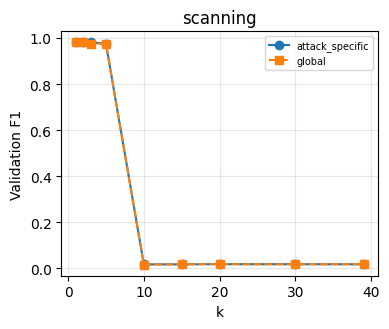

In [12]:
t_global = central_welch_t(X_train_scaled, y_train)
order_global = np.argsort(-t_global)
rows = []
for attack in ATTACKS:
    Xa, ya = binary_split(X_train_scaled, a_train, attack)
    order_spec = np.argsort(-central_welch_t(Xa, ya))
    Xv, yv = binary_split(X_val_scaled, a_val, attack)
    Xt, yt = binary_split(X_test_scaled, a_test, attack)
    Xv_ben = Xv[yv == 0]
    for s in SEEDS:
        rng = np.random.default_rng(s)
        fit_idx = rng.choice(len(X_train_benign), min(MAX_IF_FIT, len(X_train_benign)), replace=False)
        Xfit = X_train_benign[fit_idx]
        for mode, order in [("attack_specific", order_spec), ("global", order_global)]:
            for k in K_LIST_A:
                f = order[:k]
                iso = IsolationForest(n_estimators=100, random_state=s, n_jobs=-1).fit(Xfit[:, f])
                vf1, _, _ = if_metrics(iso, f, Xv_ben, Xv, yv)
                tf1, tmcc, tap = if_metrics(iso, f, Xv_ben, Xt, yt)
                rows.append(dict(attack=attack, mode=mode, k=k, seed=s,
                                 val_f1=vf1, test_f1=tf1, test_mcc=tmcc, test_prauc=tap))
    print("done", attack)
A = pd.DataFrame(rows)
A.to_csv(f"{OUT}/partA_all_runs.csv", index=False)

mean = A.groupby(["attack", "mode", "k"])[["val_f1", "test_f1", "test_mcc", "test_prauc"]].mean()
std = A.groupby(["attack", "mode", "k"])[["test_f1", "test_mcc", "test_prauc"]].std()
best = mean.groupby(["attack", "mode"]).val_f1.idxmax()          # k* chosen on VALIDATION only
tab = []
for (attack, mode), idx in best.items():
    tab.append(dict(attack=attack, mode=mode, k_star=idx[2], val_f1=mean.loc[idx, "val_f1"],
                    test_f1=mean.loc[idx, "test_f1"], test_f1_std=std.loc[idx, "test_f1"],
                    test_mcc=mean.loc[idx, "test_mcc"], test_prauc=mean.loc[idx, "test_prauc"],
                    test_f1_all_features=mean.loc[(attack, mode, n_feat), "test_f1"]))
TA = pd.DataFrame(tab).round(4)
TA.to_csv(f"{OUT}/partA_table.csv", index=False)
print(TA.to_string(index=False))

fig, axs = plt.subplots(1, len(ATTACKS), figsize=(4 * len(ATTACKS), 3.4), sharey=True)
axs = np.atleast_1d(axs)
for ax, a in zip(axs, ATTACKS):
    for mode, mk in [("attack_specific", "o-"), ("global", "s--")]:
        g = mean.loc[(a, mode)].val_f1
        ax.plot(g.index, g.values, mk, label=mode)
    ax.set_title(a); ax.set_xlabel("k"); ax.grid(alpha=.3)
axs[0].set_ylabel("Validation F1"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_global_vs_attack_specific.png", dpi=200); plt.show()

Client sizes: [42520, 1345, 22475, 14585, 99075]


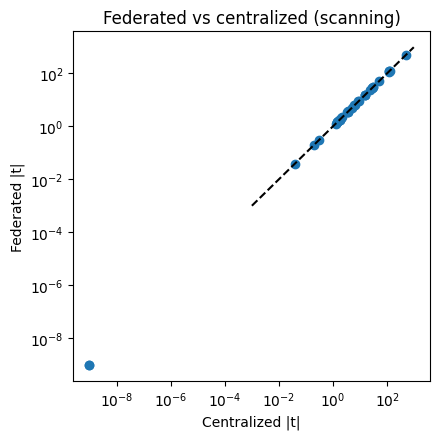

  attack  spearman  max_abs_diff  top10_same    top_feature
scanning       1.0  8.793108e-10        True TCP_WIN_MAX_IN
  attack  fed_bytes  raw_upload_bytes
scanning       6320          57269440


In [13]:
codes_tr = pd.factorize(a_train)[0]
rng = np.random.default_rng(0)
clients_idx = dirichlet_partition(codes_tr, N_CLIENTS, ALPHA, rng)
print("Client sizes:", [len(c) for c in clients_idx])

sel_rows, comm_rows, order_by_attack = [], [], {}
for attack in ATTACKS:
    cstats, raw_bytes = [], 0
    for cidx in clients_idx:
        mm = cidx[np.isin(a_train[cidx], ["benign", attack])]
        cstats.append(local_stats(X_train_scaled[mm], (a_train[mm] == attack).astype(int)))
        raw_bytes += len(mm) * (n_feat + 1) * 8
    t_fed = fed_welch_t(cstats)
    Xa, ya = binary_split(X_train_scaled, a_train, attack)
    t_cen = central_welch_t(Xa, ya)
    order_by_attack[attack] = np.argsort(-t_fed)
    sel_rows.append(dict(attack=attack, spearman=stats.spearmanr(t_cen, t_fed).correlation,
                         max_abs_diff=float(np.max(np.abs(t_cen - t_fed))),
                         top10_same=set(np.argsort(-t_cen)[:10]) == set(order_by_attack[attack][:10]),
                         top_feature=feat_names[order_by_attack[attack][0]]))
    comm_rows.append(dict(attack=attack, fed_bytes=N_CLIENTS * 2 * (1 + 2 * n_feat) * 8, raw_upload_bytes=raw_bytes))
    if attack == ATTACKS[0]:
        plt.figure(figsize=(4.5, 4.5))
        plt.loglog(t_cen + 1e-9, t_fed + 1e-9, "o")
        lim = [1e-3, max(t_cen.max(), 1) * 2]; plt.plot(lim, lim, "k--")
        plt.xlabel("Centralized |t|"); plt.ylabel("Federated |t|"); plt.title(f"Federated vs centralized ({attack})")
        plt.tight_layout(); plt.savefig(f"{OUT}/fig2_fed_vs_central_ttest.png", dpi=200); plt.show()
SEL = pd.DataFrame(sel_rows); COMM_SEL = pd.DataFrame(comm_rows)
SEL.to_csv(f"{OUT}/fedsel_check.csv", index=False); COMM_SEL.to_csv(f"{OUT}/comm_fedsel.csv", index=False)
print(SEL.to_string(index=False)); print(COMM_SEL.to_string(index=False))

In [14]:
import torch, torch.nn as nn
torch.set_num_threads(4)

class AE(nn.Module):
    def __init__(self, k):
        super().__init__()
        b = min(16, max(2, k // 2))        # bottleneck must be narrower than the input
        self.net = nn.Sequential(
            nn.Linear(k, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, b), nn.ReLU(),
            nn.Linear(b, 32), nn.ReLU(), nn.Linear(32, 64), nn.ReLU(), nn.Linear(64, k))
    def forward(self, x): return self.net(x)

def train_ae(model, Xn, epochs):
    Xt_ = torch.from_numpy(Xn.astype(np.float32))
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    model.train()
    for _ in range(epochs):
        perm = torch.randperm(len(Xt_))
        for i in range(0, len(Xt_), BATCH):
            xb = Xt_[perm[i:i + BATCH]]
            loss = ((model(xb) - xb) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()

@torch.no_grad()
def recon_err(model, Xn):
    model.eval()
    x = torch.from_numpy(Xn.astype(np.float32))
    return ((model(x) - x) ** 2).mean(1).numpy()

def evaluate_ae(model, Xval_ben, Xe, ye):
    thr = np.percentile(recon_err(model, Xval_ben), 95)      # from VALIDATION benign only
    e = recon_err(model, Xe)
    pred = (e > thr).astype(int)
    return dict(f1=f1_score(ye, pred), mcc=matthews_corrcoef(ye, pred), prauc=average_precision_score(ye, e))

def model_bytes(m):
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); return buf.getbuffer().nbytes

def fedavg_train(k, client_X, Xval_ben, Xe, ye, log):
    gm, hist, used = AE(k), [], 0
    for r in range(ROUNDS):
        states, sizes = [], []
        for Xc in client_X:
            if len(Xc) < 10: continue
            lm = copy.deepcopy(gm); train_ae(lm, Xc, LOCAL_EPOCHS)
            states.append(lm.state_dict()); sizes.append(len(Xc))
        tot = sum(sizes); used = len(sizes)
        gm.load_state_dict({key: sum(s[key] * n for s, n in zip(states, sizes)) / tot for key in states[0]})
        if log: hist.append(evaluate_ae(gm, Xval_ben, Xe, ye)["f1"])
    return gm, hist, used

In [15]:
CHUNK, CHUNKS_PER_PHASE, ATTACK_FRAC = 1500, 10, 0.3   # flows per chunk, chunks per phase, attack share
K_ADAPT = 10                      # features used by the detector
INIT_EPOCHS, RETRAIN_EPOCHS = 15, 60
WINDOW_CHUNKS = 4                 # retrain on the last 4 chunks
PERIOD = 5                        # periodic strategy: retrain every 5 chunks
COOLDOWN = 2                      # min chunks between drift-triggered retrains
SEEDS_ADAPT = [0, 1, 2]
BENIGN_SETS = [[0, 1], [2, 3], [4, 0], [1, 2]]          # normal-traffic clusters active in each phase
STRATEGIES = ["static", "periodic", "drift", "drift_rerank"]

# Stream pools come from val+test (the initial model was trained on train only)
X_pool = np.vstack([X_val_scaled, X_test_scaled])
y_pool = np.concatenate([y_val, y_test])
a_pool = np.concatenate([a_val, a_test])

# Normal-traffic profile drift: cluster benign traffic, change which clusters are active per phase
km_ad = KMeans(5, n_init=3, random_state=0).fit(X_train_benign[:50000])
ben_cl_train = km_ad.predict(X_train_benign)
pool_ben = np.where(y_pool == 0)[0]
pool_ben_cl = km_ad.predict(X_pool[pool_ben])

def benign_pool_for(p):
    ids = pool_ben[np.isin(pool_ben_cl, BENIGN_SETS[p % len(BENIGN_SETS)])]
    return ids if len(ids) >= 50 else pool_ben

def build_stream(seed):
    """Phase p: attack type ATTACKS[p] + benign profile BENIGN_SETS[p]. Returns list of (phase, row indices)."""
    rng = np.random.default_rng(seed); chunks = []
    na = int(CHUNK * ATTACK_FRAC); nb = CHUNK - na
    for p, attack in enumerate(ATTACKS):
        bp, ap = benign_pool_for(p), np.where(a_pool == attack)[0]
        for _ in range(CHUNKS_PER_PHASE):
            idx = np.concatenate([rng.choice(bp, nb, replace=len(bp) < nb),
                                  rng.choice(ap, na, replace=len(ap) < na)])
            rng.shuffle(idx); chunks.append((p, idx))
    return chunks

class DriftMonitor:
    """ADWIN (river) on per-flow errors if available, otherwise Page-Hinkley on per-chunk error rate."""
    def __init__(self):
        self.kind = "ph"
        try:
            from river import drift
            self.ad = drift.ADWIN(); self.kind = "adwin"
        except Exception:
            pass
        self.n, self.mean, self.cum, self.min_cum = 0, 0.0, 0.0, 0.0
    def update(self, errs):
        if self.kind == "adwin":
            hit = False
            for e in errs:
                r = self.ad.update(float(e))
                d = getattr(self.ad, "drift_detected", None)
                if d is None: d = bool(r[0]) if isinstance(r, tuple) else False
                hit = hit or bool(d)
            return hit
        x = float(np.mean(errs)); self.n += 1
        self.mean += (x - self.mean) / self.n
        self.cum += x - self.mean - 0.005
        self.min_cum = min(self.min_cum, self.cum)
        return (self.cum - self.min_cum) > 0.3

def fit_detector(Xb, f, epochs, seed):
    """Train an autoencoder on benign flows using features f; threshold = 95th pct on held-out benign."""
    rng = np.random.default_rng(seed); idx = rng.permutation(len(Xb))
    ntr = max(int(0.8 * len(Xb)), 1)
    m = AE(len(f)); train_ae(m, Xb[idx[:ntr]][:, f], epochs)
    hold = Xb[idx[ntr:]] if len(Xb) - ntr >= 20 else Xb[idx[:ntr]]
    return dict(model=m, f=np.array(f), thr=np.percentile(recon_err(m, hold[:, f]), 95))

def predict_det(det, X):
    return (recon_err(det["model"], X[:, det["f"]]) > det["thr"]).astype(int)

def run_strategy(name, chunks, seed):
    torch.manual_seed(seed)
    f0 = order_by_attack[ATTACKS[0]][:K_ADAPT]                 # initial attack-specific features
    init_b = X_train_benign[np.isin(ben_cl_train, BENIGN_SETS[0])]
    if len(init_b) < 500: init_b = X_train_benign
    det = fit_detector(init_b, f0, INIT_EPOCHS, seed)
    mon, buf, since, retrains, rt_time, log = DriftMonitor(), deque(maxlen=WINDOW_CHUNKS), 99, 0, 0.0, []
    for t, (p, idx) in enumerate(chunks):
        X, y = X_pool[idx], y_pool[idx]
        pred = predict_det(det, X)                              # 1) predict with the current model
        tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
        fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
        f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
        fpr = fp / max(fp + tn, 1); err = pred != y
        buf.append((X, y)); since += 1                          # 2) labels revealed after the chunk
        do = False
        if name == "periodic": do = (t + 1) % PERIOD == 0
        elif name in ("drift", "drift_rerank"): do = mon.update(err) and since >= COOLDOWN
        if do:
            Xw = np.vstack([b[0] for b in buf]); yw = np.concatenate([b[1] for b in buf])
            f = det["f"]
            if name == "drift_rerank" and yw.sum() > 20 and (yw == 0).sum() > 20:
                f = np.argsort(-central_welch_t(Xw, yw))[:K_ADAPT]          # re-rank features on recent data
            t0 = time.perf_counter()
            det = fit_detector(Xw[yw == 0], f, RETRAIN_EPOCHS, seed)
            rt_time += time.perf_counter() - t0; retrains += 1; since = 0; mon = DriftMonitor()
        log.append(dict(seed=seed, strategy=name, chunk=t, phase=p, f1=f1, fpr=fpr,
                        err=float(err.mean()), retrained=bool(do)))
    return log, retrains, rt_time

In [16]:
all_logs, cost = [], []
for seed in SEEDS_ADAPT:
    chunks = build_stream(seed)
    for name in STRATEGIES:
        log, n_re, rt = run_strategy(name, chunks, seed)
        all_logs += log; cost.append(dict(seed=seed, strategy=name, retrains=n_re, retrain_seconds=rt))
        print(f"seed {seed} | {name:13s} | mean F1 {np.mean([l['f1'] for l in log]):.3f} | retrains {n_re} | {rt:.1f}s")
LOG = pd.DataFrame(all_logs); COST = pd.DataFrame(cost)
LOG.to_csv(f"{OUT}/adapt_log.csv", index=False); COST.to_csv(f"{OUT}/adapt_cost.csv", index=False)

seed 0 | static        | mean F1 0.948 | retrains 0 | 0.0s
seed 0 | periodic      | mean F1 0.947 | retrains 2 | 2.0s
seed 0 | drift         | mean F1 0.948 | retrains 0 | 0.0s
seed 0 | drift_rerank  | mean F1 0.948 | retrains 0 | 0.0s
seed 1 | static        | mean F1 0.948 | retrains 0 | 0.0s
seed 1 | periodic      | mean F1 0.945 | retrains 2 | 1.9s
seed 1 | drift         | mean F1 0.948 | retrains 0 | 0.0s
seed 1 | drift_rerank  | mean F1 0.948 | retrains 0 | 0.0s
seed 2 | static        | mean F1 0.941 | retrains 0 | 0.0s
seed 2 | periodic      | mean F1 0.936 | retrains 2 | 2.0s
seed 2 | drift         | mean F1 0.941 | retrains 0 | 0.0s
seed 2 | drift_rerank  | mean F1 0.941 | retrains 0 | 0.0s


              mean_f1  mean_fpr  f1_just_after_drift  retrains  \
strategy                                                         
static         0.9461    0.0485                  NaN       0.0   
periodic       0.9427    0.0516                  NaN       2.0   
drift          0.9461    0.0485                  NaN       0.0   
drift_rerank   0.9461    0.0485                  NaN       0.0   

              retrain_seconds  
strategy                       
static                 0.0000  
periodic               1.9552  
drift                  0.0000  
drift_rerank           0.0000  


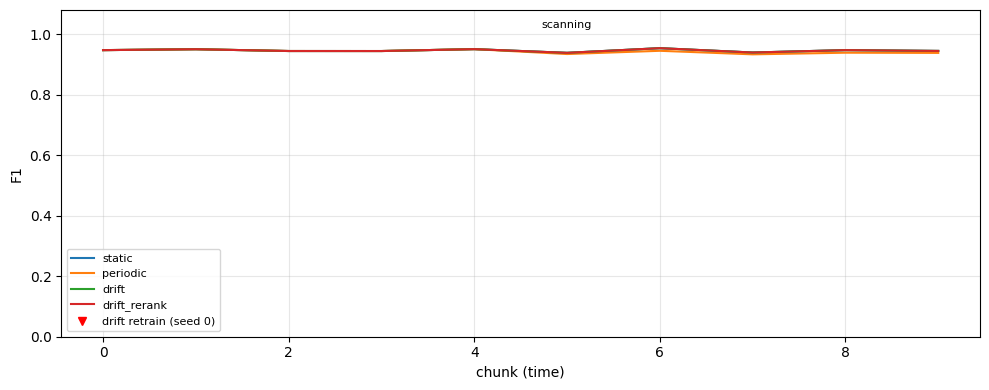

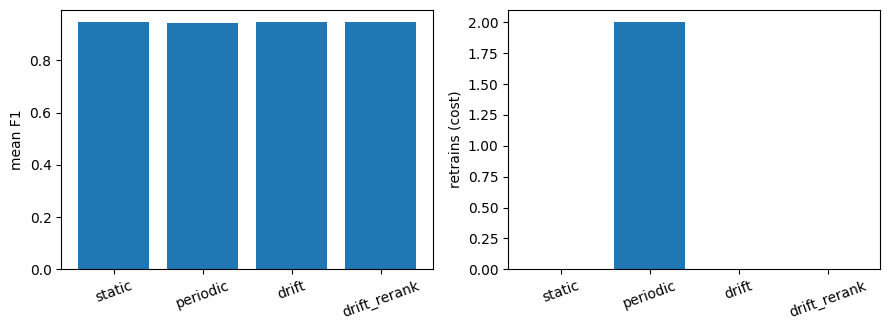

      phase  overlap_with_phase1  overlap_with_previous
0  scanning                  1.0                    1.0


In [17]:
LOG["pos"] = LOG.chunk % CHUNKS_PER_PHASE
summ = LOG.groupby("strategy").agg(mean_f1=("f1", "mean"), mean_fpr=("fpr", "mean")).join(
    LOG[(LOG.phase >= 1) & (LOG.pos < 3)].groupby("strategy").f1.mean().rename("f1_just_after_drift")).join(
    COST.groupby("strategy")[["retrains", "retrain_seconds"]].mean()).loc[STRATEGIES].round(4)
summ.to_csv(f"{OUT}/adapt_summary.csv"); print(summ)

fig, ax = plt.subplots(figsize=(10, 4))
for name in STRATEGIES:
    g = LOG[LOG.strategy == name].groupby("chunk").f1.mean()
    ax.plot(g.index, g.values, label=name)
for p in range(1, len(ATTACKS)):
    ax.axvline(p * CHUNKS_PER_PHASE - 0.5, color="k", ls=":", alpha=.5)
for p, a in enumerate(ATTACKS):
    ax.text(p * CHUNKS_PER_PHASE + CHUNKS_PER_PHASE / 2, 1.02, a, ha="center", fontsize=8)
ev = LOG[(LOG.seed == SEEDS_ADAPT[0]) & (LOG.strategy == "drift") & LOG.retrained].chunk
ax.plot(ev, [0.02] * len(ev), "v", color="red", label="drift retrain (seed 0)")
ax.set_xlabel("chunk (time)"); ax.set_ylabel("F1"); ax.set_ylim(0, 1.08); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig5_adaptive_f1_over_time.png", dpi=200); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
axs[0].bar(summ.index, summ.mean_f1); axs[0].set_ylabel("mean F1"); axs[0].tick_params(axis="x", rotation=20)
axs[1].bar(summ.index, summ.retrains); axs[1].set_ylabel("retrains (cost)"); axs[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(f"{OUT}/fig6_adaptive_accuracy_vs_cost.png", dpi=200); plt.show()

# Do the important features change as the attack changes? (top-10 overlap with phase 1)
ch = build_stream(0); tops = []
for p in range(len(ATTACKS)):
    ii = np.concatenate([idx for ph, idx in ch if ph == p])
    tops.append(set(np.argsort(-central_welch_t(X_pool[ii], y_pool[ii]))[:10]))
stab = pd.DataFrame([dict(phase=ATTACKS[p], overlap_with_phase1=len(tops[p] & tops[0]) / 10,
                          overlap_with_previous=len(tops[p] & tops[p - 1]) / 10 if p else 1.0)
                     for p in range(len(ATTACKS))])
stab.to_csv(f"{OUT}/adapt_feature_stability.csv", index=False); print(stab)

seed 0 scanning  k= 5 | F1 central 0.976 local 0.623 fed 0.976
seed 0 scanning  k=10 | F1 central 0.962 local 0.409 fed 0.961
seed 0 scanning  k=15 | F1 central 0.961 local 0.242 fed 0.963
seed 0 scanning  k=39 | F1 central 0.963 local 0.231 fed 0.962
seed 1 scanning  k= 5 | F1 central 0.976 local 0.797 fed 0.976
seed 1 scanning  k=10 | F1 central 0.962 local 0.583 fed 0.962
seed 1 scanning  k=15 | F1 central 0.962 local 0.582 fed 0.961
seed 1 scanning  k=39 | F1 central 0.962 local 0.212 fed 0.962
seed 2 scanning  k= 5 | F1 central 0.976 local 0.971 fed 0.976
seed 2 scanning  k=10 | F1 central 0.962 local 0.585 fed 0.961
seed 2 scanning  k=15 | F1 central 0.962 local 0.584 fed 0.962
seed 2 scanning  k=39 | F1 central 0.962 local 0.418 fed 0.962
                             f1             mcc           prauc        
                           mean     std    mean     std    mean     std
attack   k  setting                                                    
scanning 5  centralized  0.9

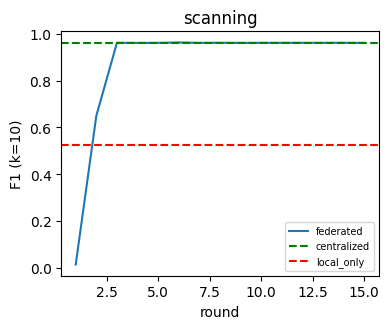

In [18]:
res, rounds_log = [], []
E = ROUNDS * LOCAL_EPOCHS                      # same total epochs for centralized and local-only
ben_idx = np.where(y_train == 0)[0]
for seed in SEEDS:
    rng = np.random.default_rng(seed); torch.manual_seed(seed)
    # benign clients: feature-space skew (KMeans clusters of normal traffic spread by Dirichlet)
    km = KMeans(5, n_init=3, random_state=seed).fit(X_train_scaled[ben_idx[:50000]])
    parts = dirichlet_partition(km.predict(X_train_scaled[ben_idx]), N_CLIENTS, ALPHA, rng)
    ben_clients = [X_train_scaled[ben_idx[p]] for p in parts]
    for attack in ATTACKS:
        order = order_by_attack[attack]                     # federated ranking from cell 5
        Xv, yv = binary_split(X_val_scaled, a_val, attack)
        Xt, yt = binary_split(X_test_scaled, a_test, attack)
        Xv_ben = Xv[yv == 0]
        for k in K_LIST_B:
            f = order[:k]
            cX = [c[:, f] for c in ben_clients]
            m = AE(k); train_ae(m, X_train_benign[:, f], E)                      # centralized
            res.append(dict(seed=seed, attack=attack, k=k, setting="centralized", **evaluate_ae(m, Xv_ben[:, f], Xt[:, f], yt)))
            loc = []                                                              # local-only
            for Xc in cX:
                if len(Xc) < 50: continue
                lm = AE(k); train_ae(lm, Xc, E); loc.append(evaluate_ae(lm, Xv_ben[:, f], Xt[:, f], yt))
            res.append(dict(seed=seed, attack=attack, k=k, setting="local_only",
                            **{kk: np.mean([x[kk] for x in loc]) for kk in loc[0]}))
            gm, hist, used = fedavg_train(k, cX, Xv_ben[:, f], Xt[:, f], yt, log=(k == K_MAIN))   # federated
            mb = model_bytes(gm)
            res.append(dict(seed=seed, attack=attack, k=k, setting="federated",
                            **evaluate_ae(gm, Xv_ben[:, f], Xt[:, f], yt), model_bytes=mb, comm_bytes=ROUNDS * used * 2 * mb))
            for i, h in enumerate(hist): rounds_log.append(dict(seed=seed, attack=attack, round=i + 1, f1=h))
            print(f"seed {seed} {attack:9s} k={k:2d} | F1 central {res[-3]['f1']:.3f} local {res[-2]['f1']:.3f} fed {res[-1]['f1']:.3f}")
R = pd.DataFrame(res); R.to_csv(f"{OUT}/fl_results.csv", index=False)
RL = pd.DataFrame(rounds_log); RL.to_csv(f"{OUT}/fl_rounds.csv", index=False)
summ_fl = R.groupby(["attack", "k", "setting"])[["f1", "mcc", "prauc"]].agg(["mean", "std"]).round(4)
summ_fl.to_csv(f"{OUT}/table_fl_summary.csv"); print(summ_fl)

fig, axs = plt.subplots(1, len(ATTACKS), figsize=(4 * len(ATTACKS), 3.4), sharey=True)
axs = np.atleast_1d(axs)
for ax, a in zip(axs, ATTACKS):
    g = RL[RL.attack == a].groupby("round").f1.mean()
    ax.plot(g.index, g.values, label="federated")
    for s_, c in [("centralized", "g"), ("local_only", "r")]:
        ax.axhline(R[(R.attack == a) & (R.k == K_MAIN) & (R.setting == s_)].f1.mean(), color=c, ls="--", label=s_)
    ax.set_title(a); ax.set_xlabel("round")
axs[0].set_ylabel(f"F1 (k={K_MAIN})"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/fig3_f1_per_round.png", dpi=200); plt.show()

k=5: AE 0.095 ms/flow, IF 7.141 ms/flow
k=10: AE 0.090 ms/flow, IF 7.324 ms/flow
k=15: AE 0.099 ms/flow, IF 7.412 ms/flow
k=39: AE 0.088 ms/flow, IF 7.501 ms/flow


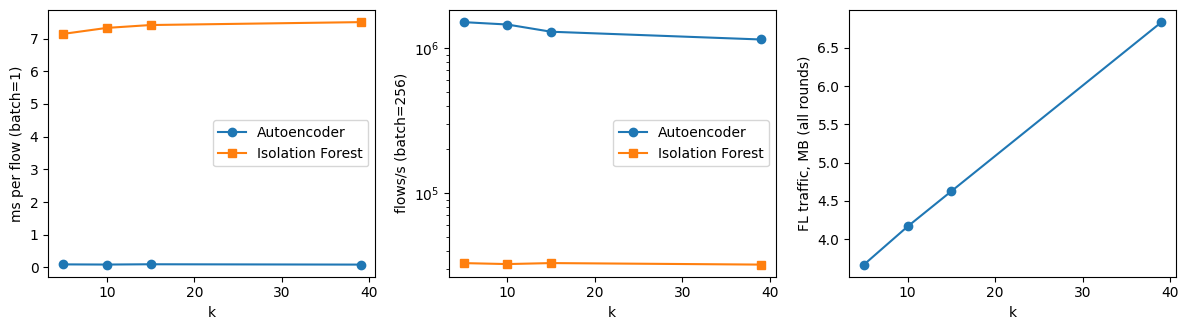

 k  ae_latency_ms  ae_flows_per_s  ae_params  ae_size_bytes  if_latency_ms  if_flows_per_s  if_size_bytes
 5         0.0951    1509319.7096       5063          24447         7.1410      32851.4951         151519
10         0.0898    1453143.0394       5903          27775         7.3245      32346.8009         336301
15         0.0987    1295870.7467       6678          30847         7.4124      32862.7186         334448
39         0.0884    1145558.4351      10359          45567         7.5013      32078.6383         345938

All results saved in results_day2/


In [19]:
def bench(attack):
    torch.set_num_threads(1)                    # single thread as a proxy for a weak IoT device
    order = order_by_attack[attack]
    Xt, _ = binary_split(X_test_scaled, a_test, attack)
    rows = []
    for k in K_LIST_B:
        f = order[:k]
        ifo = IsolationForest(n_estimators=100, random_state=0, n_jobs=1).fit(X_train_benign[:20000][:, f])
        ae = AE(k).eval()
        Z = Xt[:, f].astype(np.float32)
        n1, nb = min(1000, len(Z)), min(20000, len(Z))
        with torch.no_grad():
            for i in range(50): ae(torch.from_numpy(Z[i:i + 1]))
            t0 = time.perf_counter()
            for i in range(n1): ae(torch.from_numpy(Z[i:i + 1]))
            ae_lat = 1000 * (time.perf_counter() - t0) / n1
            t0 = time.perf_counter()
            for i in range(0, nb, 256): ae(torch.from_numpy(Z[i:i + 256]))
            ae_thr = nb / (time.perf_counter() - t0)
        n2 = min(300, len(Z)); t0 = time.perf_counter()
        for i in range(n2): ifo.score_samples(Z[i:i + 1])
        if_lat = 1000 * (time.perf_counter() - t0) / n2
        t0 = time.perf_counter()
        for i in range(0, nb, 256): ifo.score_samples(Z[i:i + 256])
        if_thr = nb / (time.perf_counter() - t0)
        rows.append(dict(k=k, ae_latency_ms=ae_lat, ae_flows_per_s=ae_thr, ae_params=sum(p.numel() for p in ae.parameters()),
                         ae_size_bytes=model_bytes(ae), if_latency_ms=if_lat, if_flows_per_s=if_thr,
                         if_size_bytes=len(pickle.dumps(ifo))))
        print(f"k={k}: AE {ae_lat:.3f} ms/flow, IF {if_lat:.3f} ms/flow")
    return pd.DataFrame(rows)

B = bench(ATTACKS[0]); B.to_csv(f"{OUT}/bench.csv", index=False)
C = R[R.setting == "federated"].groupby("k").comm_bytes.mean()
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
axs[0].plot(B.k, B.ae_latency_ms, "o-", label="Autoencoder"); axs[0].plot(B.k, B.if_latency_ms, "s-", label="Isolation Forest")
axs[0].set_xlabel("k"); axs[0].set_ylabel("ms per flow (batch=1)"); axs[0].legend()
axs[1].plot(B.k, B.ae_flows_per_s, "o-", label="Autoencoder"); axs[1].plot(B.k, B.if_flows_per_s, "s-", label="Isolation Forest")
axs[1].set_xlabel("k"); axs[1].set_ylabel("flows/s (batch=256)"); axs[1].set_yscale("log"); axs[1].legend()
axs[2].plot(C.index, C.values / 1e6, "o-"); axs[2].set_xlabel("k"); axs[2].set_ylabel("FL traffic, MB (all rounds)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig4_latency_comm_vs_k.png", dpi=200); plt.show()
print(B.round(4).to_string(index=False))
print(f"\nAll results saved in {OUT}/")